<a href="https://colab.research.google.com/github/ruqayaahabib/Advanced-AI-Labs/blob/main/Lab2_Ruqaya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

1. Load the Wine dataset into a DataFrame.

In [ ]:
# Load the Wine dataset
wine = load_wine(as_frame=True)

# Create a DataFrame
df_raw = wine.frame.copy()

# Rename the target column
df_raw = df_raw.rename(columns={"target": "wine_class"})

# Add readable class names
class_name_map = {i: name for i, name in enumerate(wine.target_names)}
df_raw["wine_class_name"] = df_raw["wine_class"].map(class_name_map)

df_raw.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


2. Create the dirty teaching copy using make_dirty_wine_dataset().

In [ ]:
def make_dirty_wine_dataset(clean_df, random_state=42):
    """
    Create a controlled dirty version of the Wine dataset.
    """

    rng = np.random.default_rng(random_state)
    df_dirty = clean_df.copy()

    # Add ID column
    df_dirty.insert(0, "sample_id", np.arange(1, len(df_dirty) + 1))

    # Create alcohol level category
    df_dirty["alcohol_level"] = pd.cut(
        df_dirty["alcohol"],
        bins=[0, 12.5, 13.5, np.inf],
        labels=["low", "medium", "high"]
    ).astype("object")

    # Add inconsistent categories
    df_dirty.loc[0, "alcohol_level"] = "High "
    df_dirty.loc[1, "alcohol_level"] = "high"
    df_dirty.loc[2, "alcohol_level"] = "MEDIUM"
    df_dirty.loc[3, "alcohol_level"] = " medium "
    df_dirty.loc[4, "alcohol_level"] = "Low"
    df_dirty.loc[5, "alcohol_level"] = "unknown"

    # Add missing values
    missing_plan = {
        "alcohol": 8,
        "malic_acid": 10,
        "flavanoids": 9,
        "proline": 7
    }

    for column, n_missing in missing_plan.items():
        missing_rows = rng.choice(
            df_dirty.index,
            size=n_missing,
            replace=False
        )
        df_dirty.loc[missing_rows, column] = np.nan

    # Add missing categorical values
    cat_missing_rows = rng.choice(
        df_dirty.index,
        size=5,
        replace=False
    )
    df_dirty.loc[cat_missing_rows, "alcohol_level"] = np.nan

    # Add invalid negative values
    df_dirty.loc[8, "alcohol"] = -13.0
    df_dirty.loc[12, "proline"] = -999.0

    # Add outliers
    df_dirty.loc[20, "proline"] = 5000.0
    df_dirty.loc[25, "color_intensity"] = 25.0

    # Add duplicate rows
    duplicate_rows = df_dirty.iloc[[10, 30]].copy()
    df_dirty = pd.concat(
        [df_dirty, duplicate_rows],
        ignore_index=True
    )

    return df_dirty

In [ ]:
# Create the dirty dataset

df_dirty = make_dirty_wine_dataset(df_raw)

# Check the shapes
print("Raw dataset shape:", df_raw.shape)
print("Dirty dataset shape:", df_dirty.shape)

Raw dataset shape: (178, 15)
Dirty dataset shape: (180, 17)


3. Display the first 10 rows, shape, columns, missing values, duplicate count, and descriptive statistics.

In [ ]:
# Display first 10 rows
display(df_dirty.head(10))

# Display dataset shape
print("Shape:", df_dirty.shape)

# Display column names
print("Columns:")
print(df_dirty.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df_dirty.isna().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df_dirty.duplicated().sum())

# Display descriptive statistics
display(df_dirty.describe(include="all"))

,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0,High
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0,high
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0,MEDIUM
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0,medium
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0,Low
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0,unknown
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0,high
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,NaN,0,class_0,high
8,9,-13.00,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0,high
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0,high


Shape: (180, 17)
Columns:
['sample_id', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class', 'wine_class_name', 'alcohol_level']

Missing values:
sample_id                        0
alcohol                          8
malic_acid                      10
ash                              0
alcalinity_of_ash                0
magnesium                        0
total_phenols                    0
flavanoids                      10
nonflavanoid_phenols             0
proanthocyanins                  0
color_intensity                  0
hue                              0
od280/od315_of_diluted_wines     0
proline                          7
wine_class                       0
wine_class_name                  0
alcohol_level                    5
dtype: int64

Duplicate rows:
2


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
count,180.000000,172.000000,170.000000,180.000000,180.000000,180.000000,180.000000,170.000000,180.000000,180.000000,180.000000,180.000000,180.000000,173.000000,180.000000,180,175
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,8
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,class_1,medium
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71,61
mean,88.738889,12.871221,2.296059,2.368000,19.503333,99.777778,2.302667,2.039294,0.360667,1.599667,5.184500,0.960367,2.615333,758.942197,0.927778,NaN,NaN
std,51.753861,2.138527,1.097297,0.273984,3.330306,14.208171,0.626440,0.998490,0.124320,0.575165,2.740945,0.228982,0.707274,471.974942,0.776977,NaN,NaN
min,1.000000,-13.000000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,-999.000000,0.000000,NaN,NaN
25%,43.750000,12.367500,1.575000,2.210000,17.200000,88.000000,1.747500,1.227500,0.267500,1.250000,3.240000,0.787500,1.952500,495.000000,0.000000,NaN,NaN
50%,88.500000,13.050000,1.820000,2.360000,19.500000,98.000000,2.380000,2.135000,0.340000,1.560000,4.800000,0.975000,2.780000,672.000000,1.000000,NaN,NaN
75%,133.250000,13.710000,3.030000,2.560000,21.500000,107.000000,2.800000,2.875000,0.432500,1.962500,6.212500,1.120000,3.170000,985.000000,2.000000,NaN,NaN


4. Identify the target column, identifier column, numerical columns, and categorical columns.


In [ ]:
# Identify important columns
target_column = "wine_class"
identifier_column = "sample_id"

# Get numerical columns
numerical_columns = df_dirty.select_dtypes(include=np.number).columns.tolist()

# Remove target and ID from numerical features
numerical_columns.remove(target_column)
numerical_columns.remove(identifier_column)

# Get categorical columns
categorical_columns = ["alcohol_level"]

print("Target column:", target_column)
print("Identifier column:", identifier_column)
print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Target column: wine_class
Identifier column: sample_id
Numerical columns: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Categorical columns: ['alcohol_level']


5. Create at least two missing-indicator columns.

In [ ]:
# Create missing indicators
df_dirty["alcohol_missing"] = df_dirty["alcohol"].isna().astype(int)
df_dirty["proline_missing"] = df_dirty["proline"].isna().astype(int)

# Display the indicators
df_dirty[["alcohol_missing", "proline_missing"]].head(10)

,alcohol_missing,proline_missing
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,1
8,0,0
9,0,0


6. Remove duplicate rows.

In [ ]:
# Remove duplicate rows
df_clean = df_dirty.drop_duplicates().reset_index(drop=True)

print("Duplicates after cleaning:", df_clean.duplicated().sum())
print("New shape:", df_clean.shape)

Duplicates after cleaning: 0
New shape: (178, 19)


7. Convert invalid negative values in positive-only numerical columns to missing values.

In [ ]:
# Positive only numerical columns
positive_columns = [
    "alcohol",
    "malic_acid",
    "flavanoids",
    "proline",
    "color_intensity"
]

# Convert negative values to missing values
for column in positive_columns:
    df_clean.loc[df_clean[column] < 0, column] = np.nan

print(df_clean[positive_columns].isna().sum())

alcohol             9
malic_acid         10
flavanoids          9
proline             8
color_intensity     0
dtype: int64


8. Clean inconsistent category labels in alcohol_level.

In [ ]:
# Clean alcohol level labels
df_clean["alcohol_level"] = (
    df_clean["alcohol_level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Treat unknown as missing
df_clean["alcohol_level"] = df_clean["alcohol_level"].replace(
    "unknown", pd.NA
)

print(df_clean["alcohol_level"].unique())

<StringArray>
['high', 'medium', 'low', <NA>]
Length: 4, dtype: string


9. Impute numerical missing values using the median and categorical missing values using the mode.

In [ ]:
# Numerical columns with missing values
columns_to_impute = [
    "alcohol",
    "malic_acid",
    "flavanoids",
    "proline",
    "color_intensity"
]

# Fill numerical missing values with median
for column in columns_to_impute:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)

# Fill categorical missing values with mode
alcohol_level_mode = df_clean["alcohol_level"].mode()[0]
df_clean["alcohol_level"] = df_clean["alcohol_level"].fillna(
    alcohol_level_mode
)

print("Remaining missing values:")
print(df_clean.isna().sum())

Remaining missing values:
sample_id                       0
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
wine_class                      0
wine_class_name                 0
alcohol_level                   0
alcohol_missing                 0
proline_missing                 0
dtype: int64


10. Create at least two new derived columns.

In [ ]:
# Create new derived columns
df_clean["phenol_flavanoid_ratio"] = (
    df_clean["total_phenols"] / df_clean["flavanoids"]
)

df_clean["proline_per_alcohol"] = (
    df_clean["proline"] / df_clean["alcohol"]
)

# Display new columns
df_clean[
    ["phenol_flavanoid_ratio", "proline_per_alcohol"]
].head()

,phenol_flavanoid_ratio,proline_per_alcohol
0,0.915033,74.841883
1,0.960145,79.545455
2,0.864198,90.045593
3,1.103152,102.992345
4,1.040892,55.513595


11. Use groupby() to compare at least two features by wine class.

In [ ]:
# Compare features by wine class
class_comparison = df_clean.groupby("wine_class")[
    ["alcohol", "proline"]
].mean()

class_comparison

,alcohol,proline
wine_class,,
0,13.704746,1145.355932
1,12.338310,521.380282
2,13.163958,629.895833


12.1 Create one missing-value bar chart

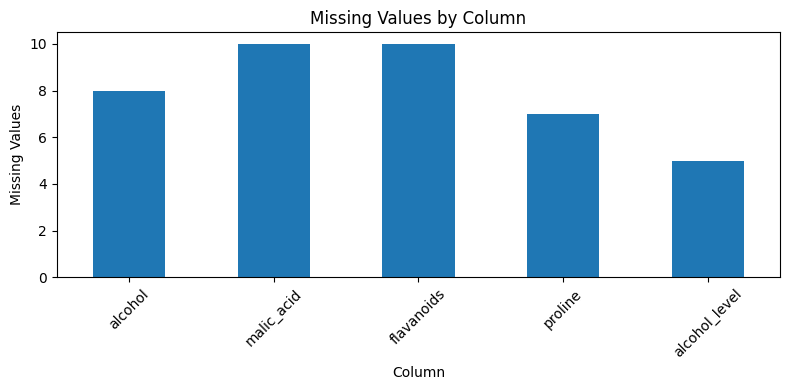

In [ ]:
# Count missing values
missing_counts = df_dirty.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

# Plot missing values
plt.figure(figsize=(8, 4))
missing_counts.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

12.2 Create one boxplot.

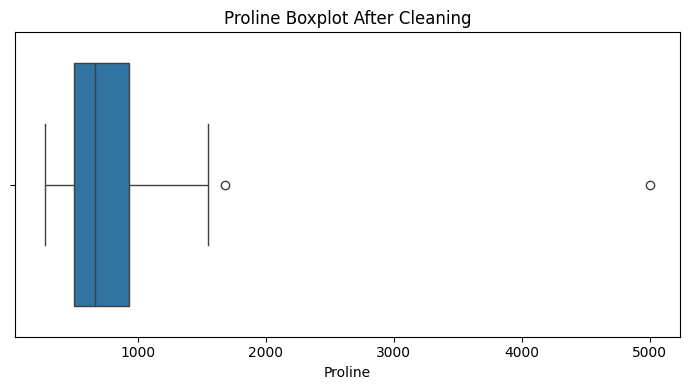

In [ ]:
# Create one boxplot
plt.figure(figsize=(7, 4))

sns.boxplot(x=df_clean["proline"])

plt.title("Proline Boxplot After Cleaning")
plt.xlabel("Proline")
plt.tight_layout()
plt.show()

13. Create one Seaborn heatmap after cleaning.

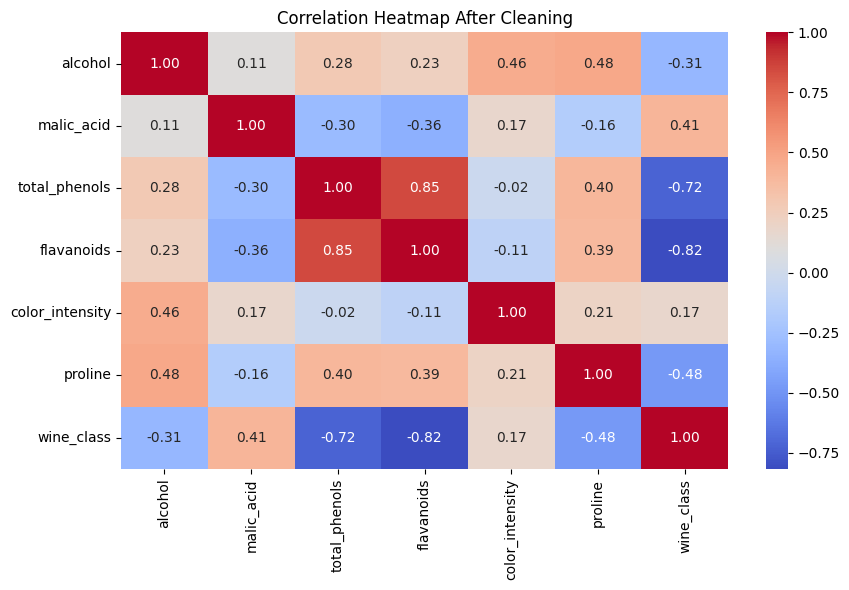

In [ ]:
# Select features for correlation
heatmap_columns = [
    "alcohol",
    "malic_acid",
    "total_phenols",
    "flavanoids",
    "color_intensity",
    "proline",
    "wine_class"
]

# Create heatmap after cleaning
plt.figure(figsize=(9, 6))

sns.heatmap(
    df_clean[heatmap_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap After Cleaning")
plt.tight_layout()
plt.show()

14. Build a leakage-safe preprocessing pipeline using train-test split and ColumnTransformer.

In [ ]:
# Separate features and target
X = df_clean.drop(columns=["wine_class", "wine_class_name"])
y = df_clean["wine_class"]

# Remove identifier
X = X.drop(columns=["sample_id"])

In [ ]:
# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'alcohol_missing', 'proline_missing', 'phenol_flavanoid_ratio', 'proline_per_alcohol']

Categorical columns:
['alcohol_level']


In [ ]:
# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (142, 18)
Test shape: (36, 18)


In [ ]:
# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [ ]:
# Fit on training data
X_train_ready = preprocessor.fit_transform(X_train)

# Transform test data
X_test_ready = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_ready.shape)
print("Processed test data shape:", X_test_ready.shape)

Processed training data shape: (142, 20)
Processed test data shape: (36, 20)


# **15. Write two short paragraphs:**

• one about the most important data-quality problem you found;

One important data quality problem was the presence of missing and invalid values. Some numerical features contained missing values, while alcohol and proline also contained invalid negative values. These problems were handled by converting invalid values to missing values and using median imputation.

• one about why safe preprocessing is important before future AI models.

Safe preprocessing is important because it prevents data leakage between the training and test datasets. The preprocessing steps should be fitted only on the training data and then applied to the test data. This helps keep the test data independent and provides a more reliable evaluation for future AI models.